In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout


In [4]:
import numpy as np
import urllib.request

url = "https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1"

urllib.request.urlretrieve(url, "bloodmnist.npz")

data = np.load("bloodmnist.npz")

x_train = data["train_images"]
y_train = data["train_labels"]

x_val = data["val_images"]
y_val = data["val_labels"]

x_test = data["test_images"]
y_test = data["test_labels"]

# Normalize images
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "Basophil", "Eosinophil", "Erythroblast",
    "Immature granulocytes", "Lymphocyte",
    "Monocyte", "Neutrophil", "Platelet"
]

image_index = 0

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (11959, 28, 28, 3) (11959, 1)
Validation: (1712, 28, 28, 3) (1712, 1)
Test: (3421, 28, 28, 3) (3421, 1)


TypeError: only 0-dimensional arrays can be converted to Python scalars

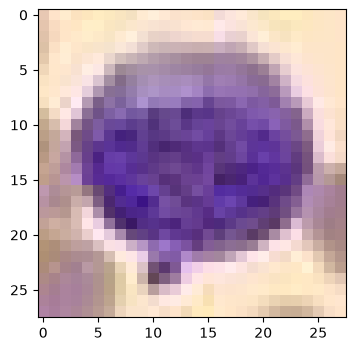

In [8]:
plt.figure(figsize=(4, 4))
plt.imshow(x_test[image_index])
plt.title(f"Input Image\nLabel: {class_names[int(y_test[image_index])]}")
plt.axis("off")
plt.show()

In [11]:
model = Sequential([
    tf.keras.Input(shape=(28, 28, 3)),
    Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1"),
    MaxPooling2D((2, 2), name="pool1"),
    Conv2D(32, (3, 3), activation="relu", padding="same", name="conv2"),
    MaxPooling2D((2, 2), name="pool2"),
    Flatten(name="flatten"),
    Dense(128, activation="relu", name="dense1"),
    Dropout(0.3, name="dropout"),
    Dense(8, activation="softmax", name="output")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                       │ (None, 28, 28, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                       │ (None, 14, 14, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 7, 7, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1568)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense1 (Dense)                       │ (None, 128)                 │         200,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 8)                   │           1,032 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 212,008 (828.16 KB)

 Trainable params: 212,008 (828.16 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=32
)

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

NameError: name 'history' is not defined

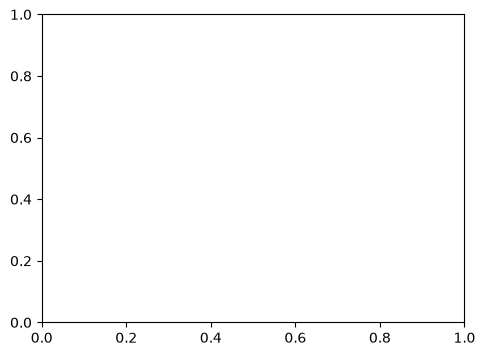

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
sample_image = x_test[image_index:image_index + 1]
prediction = model.predict(sample_image, verbose=0)
predicted_class = int(np.argmax(prediction[0]))

print(f"Actual Class    : {class_names[int(y_test[image_index])]}")
print(f"Predicted Class : {class_names[predicted_class]}")

plt.figure(figsize=(10, 4))
plt.bar(class_names, prediction[0], color="skyblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Probability")
plt.title("CNN Final Classification Probabilities")
plt.tight_layout()
plt.show()

NameError: name 'model' is not defined

In [ ]:
inp = tf.keras.Input(shape=(28, 28, 3))
x = inp
layer_outputs = []
for layer in model.layers:
    x = layer(x)
    layer_outputs.append(x)

feature_model = Model(inputs=inp, outputs=model.get_layer("conv1").output)
conv1_output = feature_model.predict(sample_image, verbose=0)

plt.figure(figsize=(16, 8))
for i in range(min(32, conv1_output.shape[-1])):
    plt.subplot(4, 8, i + 1)
    plt.imshow(conv1_output[0, :, :, i], cmap="viridis")
    plt.title(f"Filter {i + 1}", fontsize=8)
    plt.axis("off")

plt.suptitle("Conv2D Layer 1 - Feature Maps", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("layer_outputs", exist_ok=True)

activation_model = Model(
    inputs=model.inputs,
    outputs=[layer.output for layer in model.layers]
)
activations = activation_model.predict(sample_image, verbose=0)

print(f"{'Layer':<18}{'Type':<18}{'Output shape':<24}{'Params':<10}{'min':>8}{'max':>8}{'mean':>8}")
print("-" * 104)
print(f"{'input':<18}{'Input':<18}{str(sample_image.shape):<24}{0:<10}"
      f"{sample_image.min():>8.2f}{sample_image.max():>8.2f}{sample_image.mean():>8.2f}")
for layer, act in zip(model.layers, activations):
    print(f"{layer.name:<18}{type(layer).__name__:<18}{str(act.shape):<24}{layer.count_params():<10}"
          f"{act.min():>8.2f}{act.max():>8.2f}{act.mean():>8.2f}")

In [ ]:
def plot_feature_maps(act, title, filename, cmap="viridis", cols=8):
    n = act.shape[-1]
    rows = math.ceil(n / cols)
    fig = plt.figure(figsize=(cols * 1.6, rows * 1.8))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(act[0, :, :, i], cmap=cmap)
        plt.title(f"Map {i + 1}", fontsize=7)
        plt.axis("off")
    plt.suptitle(f"{title} | shape {act.shape[1:]}", fontsize=14)
    plt.tight_layout()
    fig.savefig(f"layer_outputs/{filename}.png", dpi=200, bbox_inches="tight")
    plt.show()

fig = plt.figure(figsize=(3, 3))
plt.imshow(sample_image[0])
plt.title(f"Input (28x28x3)\n{class_names[int(y_test[image_index])]}")
plt.axis("off")
fig.savefig("layer_outputs/00_input.png", dpi=200, bbox_inches="tight")
plt.show()

step = 1
for layer, act in zip(model.layers, activations):
    if act.ndim == 4:
        plot_feature_maps(act, f"{layer.name} ({type(layer).__name__})", f"{step:02d}_{layer.name}")
        step += 1

In [ ]:
def plot_kernels(layer_name, max_filters=32, cols=8):
    w = model.get_layer(layer_name).get_weights()[0]
    n = min(max_filters, w.shape[-1])
    rows = math.ceil(n / cols)
    fig = plt.figure(figsize=(cols * 1.5, rows * 1.6))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        # Show the first input channel of each RGB kernel
        plt.imshow(w[:, :, 0, i], cmap="gray")
        plt.title(f"K{i + 1}", fontsize=7)
        plt.axis("off")
    plt.suptitle(f"{layer_name} kernels (input channel 0) | weights shape {w.shape}", fontsize=13)
    plt.tight_layout()
    fig.savefig(f"layer_outputs/kernels_{layer_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_kernels("conv1")
plot_kernels("conv2", max_filters=16)

In [ ]:
conv_pool_layers = [(layer, act) for layer, act in zip(model.layers, activations) if act.ndim == 4]
fig, axes = plt.subplots(1, len(conv_pool_layers) + 1, figsize=(4 * (len(conv_pool_layers) + 1), 4))

axes[0].imshow(sample_image[0])
axes[0].set_title("Input\n28x28x3")
axes[0].axis("off")

for ax, (layer, act) in zip(axes[1:], conv_pool_layers):
    ax.imshow(act[0, :, :, 0], cmap="viridis")
    ax.set_title(f"{layer.name}\n{act.shape[1:]}")
    ax.axis("off")

plt.tight_layout()
fig.savefig("layer_outputs/pipeline_overview.png", dpi=200, bbox_inches="tight")
plt.show()